# Advanced Supervised Regression: Imputing Bloomberg's MAC3 Factors

## The real-life problem

Bloomberg replaced its old US equity factor model with **MAC3**, the multi-asset model you have been using since Week 3. MAC3 is better, but its history only goes back a few years. A quant model built on MAC3 exposures (a crash-risk score, say) cannot be backtested on 2000 or 2007, which are exactly the years you most want to test it on.

The fix is supervised regression. For the years where both exist, learn to predict each MAC3 factor from fields that **also existed in 2000**: the old US model's factors, valuation ratios, beta, returns, market cap, trading volume, sector. If the model predicts MAC3 well out of time, you can run it on 2000 and 2007 and reconstruct the missing history.

## How we will judge it

* **Out of time.** Train on 2022, 2023 and 2024; test on 2025. The test year plays the role of a year the model has never seen, the lesson from last week's random walks.
* **Spearman correlation** between predicted and actual exposures. The downstream model only uses each stock's rank on a factor, so getting the order right matters more than getting the level right.
* **Beat the naive baseline.** The old US model already has a factor with the same name for most MAC3 factors. Any model has to beat simply using it.

## The progression

1. Baseline: the old model's twin factor
2. Feature engineering: turn raw dollars into comparable features, handle missing values, scale using training years only
3. Linear regression, then Ridge and Lasso, with penalties chosen by leave-one-year-out validation
4. Many extra terms: every square and pairwise product, where regularization earns its keep
5. Diagnose the failure: Mid Cap, and the one feature that fixes it
6. Tree-based models: XGBoost and CatBoost

We work on five focus factors. The other twelve, and the trip back to 2000 and 2007, are yours.

In [ ]:
# The raw Bloomberg PORT exports (two Excel files per date, file A and file B) are licensed and not
# redistributed (see README). Place <date>_BLG_Port.xlsx and <date>_BLG_Port_2.xlsx for
# 20221130, 20231130, 20241130 and 20251130 in the working directory.
!pip install catboost -q

In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

## The data

The raw Bloomberg PORT exports, exactly as Bloomberg produced them: for each year-end, **file A** (`_BLG_Port.xlsx`) and **file B** (`_BLG_Port_2.xlsx`) list the same 1,600 stocks with different columns. The loader below reads both files, keeps the security rows, merges A and B on `Ticker`, gives the columns short names, and stacks the four years into one panel: one row per stock per year. The `mac3_` columns are the 17 targets; everything else is a candidate feature. These are licensed Bloomberg PORT exports and are not included in this repository; the README describes the columns so you can follow along with your own cross-section of stocks.

In [3]:
# Each date has two Bloomberg exports with the same 1,600 stocks: file A (_BLG_Port.xlsx) and file B (_BLG_Port_2.xlsx).
# Read both, keep only security rows, merge them on Ticker, give the columns short names, and stack the years.
US = ['Prof', 'Vol', 'Lev', 'Mom', 'Val', 'Gr', 'Dvd Yld', 'Earn Var', 'Sz']
MAC3 = ['Lqdty', 'Dvd Yld', 'Value', 'Beta', 'Prof', 'Vol', 'Residl Vol', 'Var', 'Ern Yld', 'Gwth', 'Qual',
        'LT Rev', 'Size', 'Mom', 'Lvrg', 'Mid Cap', 'Valtn']
FIELDS = [('P/S', 'ps'), ('BEst P/S BF12M', 'ps_fwd'), ('P/B', 'pb'), ('BEst P/B BF12M', 'pb_fwd'), ('P/E', 'pe'),
          ('BEst P/E BF12M', 'pe_fwd'), ('ROE LF', 'roe'), ('Beta:Y-1', 'beta_1y'), ('Total Return:Y-1', 'return_1y'),
          ('Total Return:M-3', 'return_3m'), ('Market Cap', 'market_cap'),
          ('Gr PoP of Tot Debt:Q:Q[currency=LCL], -12)', 'debt_growth'),
          ('Insider Sells Volume 1 Year:Y-1', 'insider_sells'), ('FCF Yld', 'fcf_yield'), ('FCF Yld:Q-12', 'fcf_yield_q12'),
          ('FCF Yld:Y', 'fcf_yield_y'), ('FCF Yld:Y-1', 'fcf_yield_y1'), ('Net Fixed Asset Turnover LF', 'fixed_asset_turnover'),
          ('Gr PoP of Net Fixed Asset Turnover:Y:Y, -5)', 'fixed_asset_turnover_growth'), ('Number of Employees:Y', 'employees')]
snake = lambda s: s.lower().replace(' ', '_')
num = lambda s: pd.to_numeric(s, errors='coerce')

def read_export(path):
    """One Bloomberg export: two banner rows above the header, then one row per security, then a footer."""
    df = pd.read_excel(path, skiprows=2)
    df = df[df['Ticker'].astype(str).str.endswith('Equity')].set_index('Ticker')
    return df[~df.index.duplicated()]

def load_date(date):
    a = read_export(f'{date}_BLG_Port.xlsx')
    b = read_export(f'{date}_BLG_Port_2.xlsx')
    df = a.join(b[[c for c in b.columns if c not in a.columns]], how='inner')   # merge file A and file B
    X = pd.DataFrame(index=df.index)
    X['date'] = int(date)
    X['name'] = df['Short Name']
    X['sector'] = df['GICS Sector'].astype(str).str.split('.').str[0].replace({'nan': np.nan, 'None': np.nan})
    for k in US:
        X['us_' + snake(k)] = num(df[f'PORT US {k} Fact Exp:D-1'])
    for col, short in FIELDS:
        X[short] = num(df[col]) if col in df else np.nan
    X['traded_value_1d'] = num(df['Equity Traded Val:D-1'])
    X['employees_5y_ago'] = num(df['Number of Employees:Y-5'])
    X['shares_out'] = num(df['Shares Out:Y'])
    X['shares_out_prior'] = num(df['Shares Out:Y-1'])
    X['buyback_value'] = num(df['Val Sh Repurch fr Repurch Prog:Y'])
    for c in [c for c in df.columns if str(c).startswith('BI STOX')]:
        X['stox_' + c.split('(')[0].replace('BI STOX', '').strip().lower().replace(' ', '_').replace('-', '_')] = num(df[c])
    for k in MAC3:
        col = f'PORT MAC3 {k} Factor Exp:D-1'
        X['mac3_' + snake(k)] = num(df[col]) if col in df else np.nan
    return X

P = pd.concat([load_date(d) for d in ['20221130', '20231130', '20241130', '20251130']])
P = P.rename_axis('ticker').reset_index().replace([np.inf, -np.inf], np.nan)
targets = [c for c in P.columns if c.startswith('mac3_')]
print(P.shape, '|', len(targets), 'MAC3 targets')
P.groupby('date').agg(stocks=('ticker', 'size'), with_mac3=('mac3_size', lambda s: s.notna().sum()),
                      with_old_model=('us_sz', lambda s: s.notna().sum()))

(6400, 61) | 17 MAC3 targets


,stocks,with_mac3,with_old_model
date,,,
20221130,1600,1589,1577
20231130,1600,1591,1579
20241130,1600,1592,1589
20251130,1600,1593,1591


In [4]:
focus = ['mac3_size', 'mac3_value', 'mac3_mom', 'mac3_lqdty', 'mac3_mid_cap']
train = P[P['date'] < 20251130].copy()
test = P[P['date'] == 20251130].copy()
print(len(train), 'training rows (2022-2024) |', len(test), 'test rows (2025)')

def spearman(pred, actual):
    return pd.Series(np.asarray(pred)).corr(pd.Series(np.asarray(actual)), method='spearman')

4800 training rows (2022-2024) | 1600 test rows (2025)


# Step 1: The baseline

For four of the five focus factors the old model has a twin: size, value, momentum. Liquidity's natural twin is turnover, the dollar volume traded as a share of market cap. Mid Cap has no twin, so we try the old size factor.

In [5]:
test['turnover'] = np.log(test['traded_value_1d'] / test['market_cap'])
twin = {'mac3_size': 'us_sz', 'mac3_value': 'us_val', 'mac3_mom': 'us_mom', 'mac3_lqdty': 'turnover', 'mac3_mid_cap': 'us_sz'}
results = pd.DataFrame({'baseline (twin)': {t: spearman(test[twin[t]], test[t]) for t in focus}})
results.round(3)

,baseline (twin)
mac3_size,0.764
mac3_value,0.884
mac3_mom,0.806
mac3_lqdty,0.388
mac3_mid_cap,0.165


**Reading it.** The twin works where the two models measure the same idea: Value 0.88, Momentum 0.81, Size 0.76. It is weak for Liquidity (0.39), where turnover is only a rough proxy, and useless for Mid Cap (0.17), which has no counterpart in the old model. The average across the five is 0.60. That is the bar every model below has to clear.

# Step 2: Feature engineering and preprocessing

Three jobs before any model sees the data.

**Make features comparable.** Market cap runs from a million dollars to four trillion, and a dollar figure means something different in 2022 and 2025. Logs and ratios fix that: log market cap, turnover, share-count growth, buyback yield, employee growth.

**Handle missing values honestly.** Fill each gap with the median from the training years, and add a 0/1 flag saying it was missing, because missingness itself can carry information.

**Learn every statistic from the training years only.** Winsorize at the training 1st and 99th percentiles, then standardize with a scaler fit on training rows. Anything the model learns, a median, a percentile, a scaler, a coefficient, must come from training rows. One distinction matters for this problem: a transform computed within a single date from that date's own features, such as ranking the stocks against each other, is fair, because on March 24, 2000 you will have every stock's features for that day. What you will not have is that day's MAC3.

In [6]:
def engineer(d):
    d = d.copy()
    d['log_mcap'] = np.log(d['market_cap'].where(d['market_cap'] > 0))
    d['turnover'] = np.log(d['traded_value_1d'] / d['market_cap'])
    d['share_growth'] = d['shares_out'] / d['shares_out_prior'] - 1
    d['buyback_yield'] = d['buyback_value'] / d['market_cap']
    d['employee_growth'] = d['employees'] / d['employees_5y_ago'] - 1
    d['log_employees'] = np.log(d['employees'].where(d['employees'] > 0))
    return d.replace([np.inf, -np.inf], np.nan)

train, test = engineer(train), engineer(test)
for d in (train, test):
    for s in sorted(P['sector'].dropna().unique()):
        d['sec_' + s.replace(' ', '_')] = (d['sector'] == s).astype(float)

raw_dollars = ['market_cap', 'traded_value_1d', 'shares_out', 'shares_out_prior', 'buyback_value', 'employees', 'employees_5y_ago']
sector_cols = [c for c in train.columns if c.startswith('sec_')]
features = [c for c in train.columns if c not in targets + raw_dollars + sector_cols + ['ticker', 'date', 'name', 'sector']]
print(len(features), 'numeric features +', len(sector_cols), 'sector columns')

39 numeric features + 11 sector columns


In [7]:
def preprocess(train, test, cols):
    tr, te = train[cols].copy(), test[cols].copy()
    lo, hi = tr.quantile(0.01), tr.quantile(0.99)            # training percentiles only
    tr, te = tr.clip(lo, hi, axis=1), te.clip(lo, hi, axis=1)
    med = tr.median()                                          # training medians only
    for c in cols:
        tr[c + '_missing'], te[c + '_missing'] = tr[c].isna().astype(float), te[c].isna().astype(float)
    tr[cols], te[cols] = tr[cols].fillna(med), te[cols].fillna(med)
    scaler = StandardScaler().fit(tr[cols])                    # fit on training rows only
    tr[cols], te[cols] = scaler.transform(tr[cols]), scaler.transform(te[cols])
    return (pd.concat([tr, train[sector_cols]], axis=1).fillna(0), pd.concat([te, test[sector_cols]], axis=1).fillna(0))

Xtr, Xte = preprocess(train, test, features)
print('model matrix:', Xtr.shape)

model matrix: (4800, 89)


# Step 3: Linear, Ridge and Lasso

Ridge and Lasso need a penalty strength, alpha. Choosing it with a random cross-validation split would mix the three training years together. Instead we use **leave-one-year-out**: fit on two training years, score on the third, rotate, and keep the alpha with the best average Spearman. It is the out-of-time test in miniature, run inside the training data.

In [8]:
years = train['date'].values

def leave_one_year_out(make_model, alphas, X, y, yrs):
    scores = []
    for a in alphas:
        s = [spearman(make_model(a).fit(X[yrs != yr], y[yrs != yr]).predict(X[yrs == yr]), y[yrs == yr]) for yr in np.unique(yrs)]
        scores.append(np.mean(s))
    return alphas[int(np.argmax(scores))]

def linear_family(Xtr, Xte, factors):
    out = {}
    for t in factors:
        mtr, mte = train[t].notna().values, test[t].notna().values
        Xa, ya, Xb, yb = Xtr.values[mtr], train[t].values[mtr], Xte.values[mte], test[t].values[mte]
        a_r = leave_one_year_out(lambda a: Ridge(alpha=a), list(np.logspace(-1, 4, 6)), Xa, ya, years[mtr])
        a_l = leave_one_year_out(lambda a: Lasso(alpha=a, max_iter=5000), [0.0003, 0.001, 0.003, 0.01], Xa, ya, years[mtr])
        lasso = Lasso(alpha=a_l, max_iter=5000).fit(Xa, ya)
        out[t] = {'linear': spearman(LinearRegression().fit(Xa, ya).predict(Xb), yb),
                  'ridge': spearman(Ridge(alpha=a_r).fit(Xa, ya).predict(Xb), yb),
                  'lasso': spearman(lasso.predict(Xb), yb),
                  'lasso keeps': int((lasso.coef_ != 0).sum())}
    return pd.DataFrame(out).T

lin = linear_family(Xtr, Xte, focus)
results = results.join(lin[['linear', 'ridge', 'lasso']])
print('features available to lasso:', Xtr.shape[1])
pd.concat([results, lin[['lasso keeps']]], axis=1).astype(float).round(3)

features available to lasso: 89


,baseline (twin),linear,ridge,lasso,lasso keeps
mac3_size,0.764,0.930,0.931,0.932,71.0
mac3_value,0.884,0.932,0.932,0.932,65.0
mac3_mom,0.806,0.911,0.915,0.915,47.0
mac3_lqdty,0.388,0.613,0.615,0.614,64.0
mac3_mid_cap,0.165,0.481,0.481,0.477,63.0


**Reading it.** One linear regression on all 89 columns lifts the average from 0.60 to 0.77. Size jumps from 0.76 to 0.93, Value to 0.93, Momentum to 0.91: many old-world features together beat any single twin.

Ridge and Lasso add almost nothing here (0.775 and 0.774 against 0.773). That is last week's lesson read the other way round. With 4,800 training rows and 89 curated, mostly independent features, least squares is not starved for data, so shrinkage has little variance to remove. Lasso earns something else, a simpler model: it drops between 18 and 42 of the 89 columns with no loss in accuracy.

Liquidity (0.61) and Mid Cap (0.48) are still weak, and no amount of tuning alpha will fix them.

# Step 4: Many extra terms, where regularization earns its keep

Our 89 columns are a curated set: each one chosen, logged or turned into a ratio, and the old model's factors are already close to independent of each other. Shrinkage has little to fix. Now do the opposite. Instead of thinking, throw in **every square and every pairwise product** of the numeric features (scikit-learn's `PolynomialFeatures(degree=2)`). That gives the model every curve and every interaction, and hundreds of columns that are mostly noise.

In [9]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False).fit(Xtr[features])
scaler2 = StandardScaler().fit(poly.transform(Xtr[features]))
other = [c for c in Xtr.columns if c not in features]                 # missing flags and sectors, unexpanded
Ptr = np.hstack([scaler2.transform(poly.transform(Xtr[features])), Xtr[other].values])
Pte = np.hstack([scaler2.transform(poly.transform(Xte[features])), Xte[other].values])
print('columns after the expansion:', Ptr.shape[1])

deg2 = {}
for t in focus:
    mtr, mte = train[t].notna().values, test[t].notna().values
    Xa, ya, Xb, yb = Ptr[mtr], train[t].values[mtr], Pte[mte], test[t].values[mte]
    a_r = leave_one_year_out(lambda a: Ridge(alpha=a), list(np.logspace(0, 5, 6)), Xa, ya, years[mtr])
    a_l = leave_one_year_out(lambda a: Lasso(alpha=a, max_iter=2000, tol=1e-3), [0.003, 0.01, 0.03], Xa, ya, years[mtr])
    lasso = Lasso(alpha=a_l, max_iter=2000, tol=1e-3).fit(Xa, ya)
    deg2[t] = {'linear (degree 2)': spearman(LinearRegression().fit(Xa, ya).predict(Xb), yb),
               'ridge (degree 2)': spearman(Ridge(alpha=a_r).fit(Xa, ya).predict(Xb), yb),
               'lasso (degree 2)': spearman(lasso.predict(Xb), yb),
               'lasso keeps': int((lasso.coef_ != 0).sum())}
deg2 = pd.DataFrame(deg2).T
results = results.join(deg2.drop(columns='lasso keeps'))
pd.concat([results[['linear', 'linear (degree 2)', 'ridge (degree 2)', 'lasso (degree 2)']], deg2[['lasso keeps']]], axis=1).astype(float).round(3)

columns after the expansion: 869


,linear,linear (degree 2),ridge (degree 2),lasso (degree 2),lasso keeps
mac3_size,0.930,0.902,0.919,0.935,113.0
mac3_value,0.932,0.922,0.937,0.939,322.0
mac3_mom,0.911,0.855,0.884,0.928,35.0
mac3_lqdty,0.613,0.532,0.599,0.641,197.0
mac3_mid_cap,0.481,0.656,0.715,0.799,32.0


**Reading it.** The expansion turns 39 numeric features into 869 columns. Plain least squares averages 0.77 across the five, exactly where it started, but only because the squares rescue Mid Cap (0.48 to 0.66). Everywhere else it gets worse: Size from 0.93 to 0.90, Momentum from 0.91 to 0.86, Liquidity from 0.61 to 0.53. It is fitting noise in hundreds of products.

Now regularization earns its keep. Ridge lifts the degree-2 average to 0.81. Lasso lifts it to 0.85 and is the best linear model on every factor, while keeping only 32 to 322 of the 869 columns. The squares also let Mid Cap bend: 0.48 with the curated features, 0.80 with Lasso on the expansion.

So the two halves of the lesson fit together. With a short, curated, nearly independent feature set, shrinkage has little to do. With many extra terms, most of them noise and many of them near copies of each other, shrinkage is what keeps the model honest, and Lasso, which can drop columns outright, does best.

**Aside: the same idea for paths.** A polynomial expansion turns a few features into every product of them. A **signature transform** does the same for a path, a sequence of values over time: it records every ordered product of the path's moves, which is how it captures not just where variables went but in what order. Depth 3 on 9 monthly economic series already gives hundreds of terms, which puts it in exactly the regime above, where Lasso and Ridge decide whether the expansion helps or overfits. Our panel has one snapshot per stock per year, so there is no path here; signatures come back later in the course, on time series.

# Step 5: Diagnose the failure, Mid Cap

Back to the curated features. Mid Cap barely moved in Step 3. When one factor fails, stop tuning and look at it. Plot each stock's Mid Cap exposure against its market cap, one panel per year.

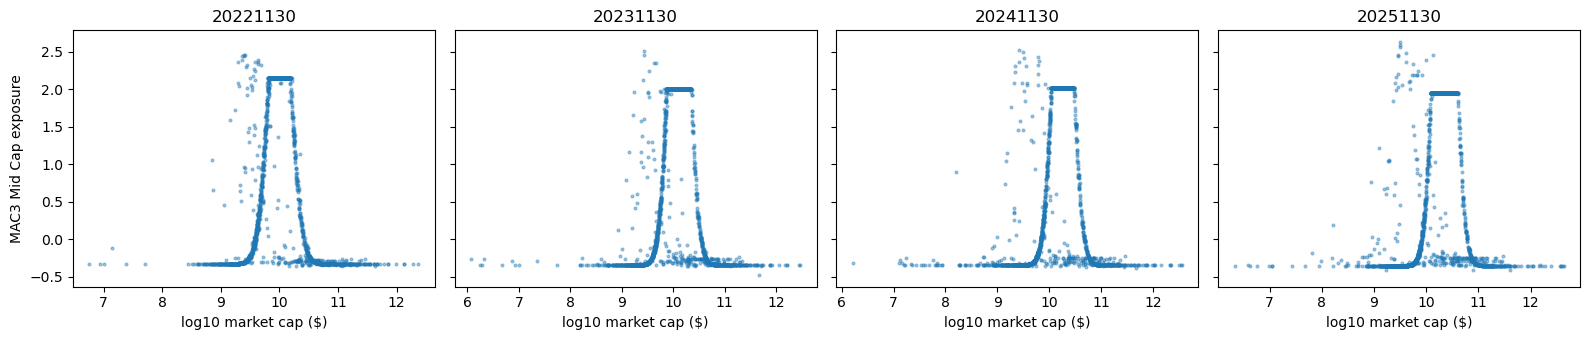

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (d, g) in zip(axes, P[P['date'] >= 20221130].groupby('date')):
    ax.scatter(np.log10(g['market_cap']), g['mac3_mid_cap'], s=4, alpha=0.4)
    ax.set_title(str(d))
    ax.set_xlabel('log10 market cap ($)')
axes[0].set_ylabel('MAC3 Mid Cap exposure')
plt.tight_layout()
plt.show()

**Reading it.** Mid Cap is not a slope; it is a plateau. Stocks in a middle band of market cap sit near +1.6 and everything else sits near -0.3. A straight line in market cap cannot draw a plateau, which is why the linear model stalls.

Now compare the four panels. The plateau slides to the right every year, from roughly $6 to $18 billion in 2022 to roughly $10 to $56 billion in 2025. A band fixed in dollars would be wrong the very next year.

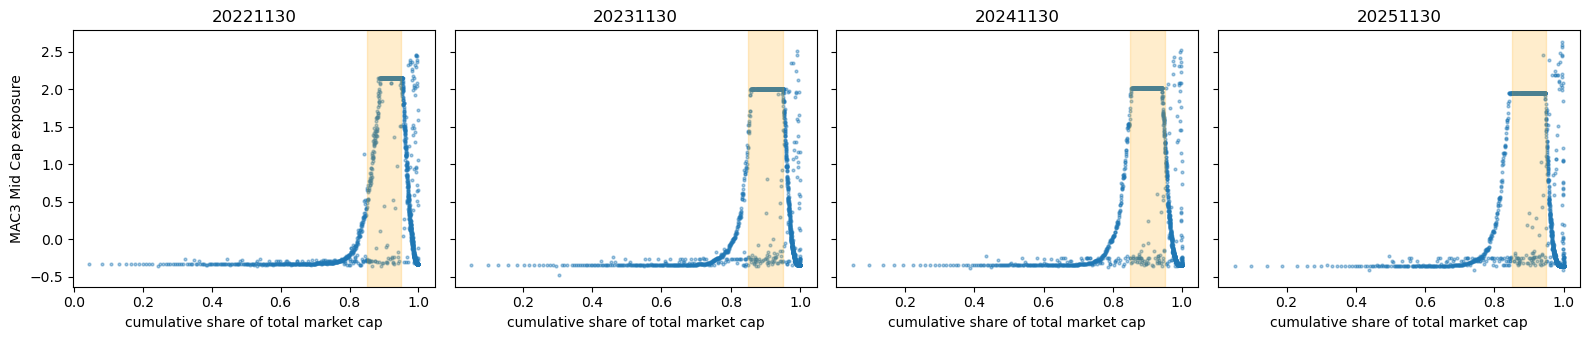

In [11]:
def cumulative_cap_share(d):
    """Share of the year's total market cap held by stocks at least as large as this one."""
    d = d.copy()
    d['cum_share'] = np.nan
    for yr, g in d[d['market_cap'].notna()].groupby('date'):
        g = g.sort_values('market_cap', ascending=False)
        d.loc[g.index, 'cum_share'] = (g['market_cap'].cumsum() / g['market_cap'].sum()).values
    return d

Pc = cumulative_cap_share(P[P['date'] >= 20221130])
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (d, g) in zip(axes, Pc.groupby('date')):
    ax.scatter(g['cum_share'], g['mac3_mid_cap'], s=4, alpha=0.4)
    ax.axvspan(0.85, 0.95, color='orange', alpha=0.2)
    ax.set_title(str(d))
    ax.set_xlabel('cumulative share of total market cap')
axes[0].set_ylabel('MAC3 Mid Cap exposure')
plt.tight_layout()
plt.show()

**Reading it.** Measure size the way an index provider does: sort the stocks from largest to smallest and ask what share of the year's total market cap sits at or above each stock. Now the plateau lines up in every year at roughly 85 to 95 percent. The mid caps are the stocks that make up the next ten percent of the market after the giants.

The dollar band moved because the market grew and concentrated: these 1,600 stocks were worth $52 trillion in 2022 and $87 trillion in 2025. The share band did not move. A feature defined the way the factor is defined travels across years, and in this problem it will have to travel a long way.

In [12]:
train, test = cumulative_cap_share(train), cumulative_cap_share(test)
for d in (train, test):
    d['cum_share_sq'] = d['cum_share'] ** 2
    d['mid_band'] = np.exp(-((d['cum_share'] - 0.90) / 0.05) ** 2)   # a bump centered on the band seen in the training years

features2 = features + ['cum_share', 'cum_share_sq', 'mid_band']
Xtr2, Xte2 = preprocess(train, test, features2)
lin2 = linear_family(Xtr2, Xte2, focus)
results = results.join(lin2[['linear', 'ridge', 'lasso']].add_suffix(' + band feature'))
results.round(3)

,baseline (twin),linear,ridge,lasso,linear (degree 2),ridge (degree 2),lasso (degree 2),linear + band feature,ridge + band feature,lasso + band feature
mac3_size,0.764,0.930,0.931,0.932,0.902,0.919,0.935,0.931,0.931,0.932
mac3_value,0.884,0.932,0.932,0.932,0.922,0.937,0.939,0.934,0.934,0.934
mac3_mom,0.806,0.911,0.915,0.915,0.855,0.884,0.928,0.911,0.915,0.920
mac3_lqdty,0.388,0.613,0.615,0.614,0.532,0.599,0.641,0.622,0.624,0.624
mac3_mid_cap,0.165,0.481,0.481,0.477,0.656,0.715,0.799,0.769,0.775,0.780


**Reading it.** One engineered feature, a bump centered on the 0.90 share read off the training years, lifts Mid Cap from 0.48 to 0.77 for linear regression and 0.78 for Lasso. Nothing else moves much, which is the point: the feature fixes the factor it was built for. The average across the five rises from 0.77 to 0.84.

Lasso on 869 blind columns reached 0.80 on Mid Cap, so why bother? Because the band is one column you can explain, and it is defined the way the factor is defined. The squares of log market cap put the hump wherever market caps sat in 2022 to 2024. The band puts it at the same share of the market in any year, which is what you need when the model has to run on years that look nothing like these.

# Step 6: Tree-based models

A gradient-boosted tree builds hundreds of small decision trees, each correcting the errors of the ones before it (the Week 9 and 10 material, previewed here). Three things change compared with a linear model:

* **Nonlinearity comes free.** A tree can learn "Mid Cap is high only between these two market caps" with no engineered bump.
* **No scaling, no imputation.** Splits only care about order, and XGBoost and CatBoost route missing values on their own.
* **Interactions come free.** A split on size followed by a split on volatility is an interaction nobody had to write down.

We give both models the engineered features (raw values, no scaling) and let them run.

In [13]:
tree_features = features2 + sector_cols
trees = {}
for t in focus:
    mtr, mte = train[t].notna(), test[t].notna()
    xgb = XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=0)
    xgb.fit(train.loc[mtr, tree_features], train.loc[mtr, t])
    cat = CatBoostRegressor(iterations=500, depth=6, learning_rate=0.05, random_seed=0, verbose=0)
    cat.fit(train.loc[mtr, tree_features], train.loc[mtr, t])
    trees[t] = {'xgboost': spearman(xgb.predict(test.loc[mte, tree_features]), test.loc[mte, t]),
                'catboost': spearman(cat.predict(test.loc[mte, tree_features]), test.loc[mte, t])}
    if t == 'mac3_mid_cap':
        midcap_model = cat
results = results.join(pd.DataFrame(trees).T)
results.loc['AVERAGE'] = results.mean()
results.round(3)

,baseline (twin),linear,ridge,lasso,linear (degree 2),ridge (degree 2),lasso (degree 2),linear + band feature,ridge + band feature,lasso + band feature,xgboost,catboost
mac3_size,0.764,0.930,0.931,0.932,0.902,0.919,0.935,0.931,0.931,0.932,0.953,0.956
mac3_value,0.884,0.932,0.932,0.932,0.922,0.937,0.939,0.934,0.934,0.934,0.960,0.959
mac3_mom,0.806,0.911,0.915,0.915,0.855,0.884,0.928,0.911,0.915,0.920,0.919,0.916
mac3_lqdty,0.388,0.613,0.615,0.614,0.532,0.599,0.641,0.622,0.624,0.624,0.665,0.664
mac3_mid_cap,0.165,0.481,0.481,0.477,0.656,0.715,0.799,0.769,0.775,0.780,0.827,0.844
AVERAGE,0.601,0.773,0.775,0.774,0.773,0.811,0.849,0.833,0.836,0.838,0.865,0.868


**Reading it.** The trees win on average, 0.87 against 0.84 for the best linear model, and they win most where the relationship is curved: Mid Cap 0.84 with CatBoost, Size 0.96, Value 0.96, Liquidity 0.66. On Momentum they tie the linear models at 0.92, because momentum is close to a straight-line function of past returns and there is nothing curved left to find. XGBoost and CatBoost land within 0.02 of each other on every factor: the family matters more than the brand.

Liquidity is still the hardest of the five at 0.66.

In [14]:
imp = pd.Series(midcap_model.get_feature_importance(), index=tree_features).sort_values(ascending=False)
imp.head(8).round(1)

mid_band         50.2
insider_sells     9.7
cum_share         4.9
cum_share_sq      3.4
log_mcap          3.4
pe_fwd            2.1
us_vol            2.1
turnover          1.4
dtype: float64

**Reading it.** Half of the model's Mid Cap decisions run through `mid_band`, the feature we engineered, with the cumulative share and log market cap behind it. That is a sanity check passing.

Then look at `insider_sells` in second place. A feature that ranks this high without an obvious story deserves a minute: insider selling volume grows with company size, so it may be acting as one more size proxy. Importance tells you what the model uses, not why, and it is where a reviewer's questions start.

Does the tree need our engineered band at all? Refit CatBoost on Mid Cap without the three band features.

In [15]:
mtr, mte = train['mac3_mid_cap'].notna(), test['mac3_mid_cap'].notna()
no_band = features + sector_cols
cat_nb = CatBoostRegressor(iterations=500, depth=6, learning_rate=0.05, random_seed=0, verbose=0)
cat_nb.fit(train.loc[mtr, no_band], train.loc[mtr, 'mac3_mid_cap'])
print(f"Mid Cap, CatBoost without the band features: {spearman(cat_nb.predict(test.loc[mte, no_band]), test.loc[mte, 'mac3_mid_cap']):.3f}")
print(f"Mid Cap, CatBoost with the band features:    {results.loc['mac3_mid_cap', 'catboost']:.3f}")

Mid Cap, CatBoost without the band features: 0.818
Mid Cap, CatBoost with the band features:    0.844


**Reading it.** Without the band, CatBoost still reaches 0.82 on Mid Cap, far above the linear model's 0.48, because trees can carve out a plateau on their own. Adding the engineered band lifts it to 0.84. Trees reduce the need for feature engineering without removing it. A feature that encodes how the factor is actually defined helps every model, and it matters most when the model has to run on years that look nothing like the training data.

# The real-life goal: MAC3 for 2000 and 2007 (Project 2)

Everything above trains on 2022 to 2024 and tests on 2025, years where Bloomberg publishes MAC3, so we could score ourselves. The real job starts where that answer key ends. MAC3 only goes back to about 2020. An analyst who wants to study the two great crashes with today's factors needs them for about 1,600 stocks on **24 March 2000** and **9 October 2007**, the two market peaks, and nobody can tell you the right answer for those dates.

That is **Project 2, option 5**. You take the best model you built today, extend it, impute MAC3 at both peaks, and then find out whether the imputed factors pick out the stocks that crashed.

## What the project data adds

The project file is today's panel plus the two peak dates. On those rows every MAC3 column is empty, and two columns are filled that today's file did not need:

| Column | Meaning |
|---|---|
| `sector` | Filled for every stock, including the many Bloomberg left blank because the company later disappeared |
| `total_return` | Each stock's total return in percent over the crash: 2000 to 2002 (24 March 2000 to 9 October 2002) or 2007 to 2009 (9 October 2007 to 9 March 2009) |

An equal-weighted portfolio of all stocks lost 46 percent over 2000 to 2002 and 58 percent over 2007 to 2009. Use `total_return` only to **evaluate**. The imputation never sees it.

## The analysts' hint

You do not need to know why markets crash; this is a computer science class. Take this as a requirement handed to you by the business:

* **Both crashes:** the most volatile stocks fell hardest.
* **2000:** the damage centred on technology (Information Technology and Communication Services), and inside it the most **expensive** stocks fell hardest.
* **2007:** the damage centred on **Financials**, and inside it the most **levered** stocks fell hardest.

## Your job

1. **Extend your best imputation model** to the factors the hint needs (volatility, value or valuation, leverage) and as many of the 17 as you can. Some will behave like Size, some like Mid Cap. Diagnose before you tune.
2. **Impute MAC3 at both peaks.** Before you trust the numbers, check what is different about those years: which features exist, how much is missing, how the market's size and shape differed, and whether each engineered feature still means the same thing.
3. **Turn the hint into a crash score** built from your imputed factors. Take your 30 and 50 riskiest stocks, hold each group as an equal-weighted portfolio over the crash, and compare its total return with the equal-weighted portfolio of all stocks.
4. **Ask whether the imputation earned its keep.** Run the same test with the old model's factors (the `us_` columns). If they do as well, say so.

## Reflection questions

1. Why is a random 80/20 split the wrong test for this problem, and why is leave-one-year-out the right way to choose alpha?
2. The downstream model only uses ranks. Why does that make Spearman the right score, and when would RMSE matter instead?
3. The old model's size factor already predicts MAC3 Size well. What does the full model add, and how would you show it is worth the complexity?
4. The mid-cap band is stable in cumulative market-cap share and drifts in dollars. Which would you trust in 2000, and why?
5. CatBoost beats the best linear model on average. Name one reason you might still ship the linear model.
6. Every preprocessing step here was fit on the training years only. Pick one step and describe exactly how it would leak if you fit it on all four years.
7. The hint names a different "expensive" or "levered" factor for each crash. If you trained a regression on the 2000 crash's total returns and used it to pick stocks to avoid in 2007, what would you expect, and what does that say about using one crash to predict the next?
